# 3 · Classification trees and ensembles for equity regimes
**Question:** can month-end macro and market indicators (momentum, volatility, VIX, term spread, credit spreads, dollar, gold) predict whether SPY rises next month? *(Spoiler: not reliably. The notebook shows how to measure that properly.)*

We compare logistic regression, a single decision tree, a random forest and gradient boosting, using an **expanding-window walk-forward**: refit every 12 months and predict only the following year. Then we test a simple timing rule: hold SPY when P(up) > 0.5, otherwise hold intermediate Treasuries (IEF).

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
load = lambda f: pd.read_csv(f"../data/{f}.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_data.py
from finml import regime
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
px = load("macro").ffill()
X = regime.monthly_features(px)
y = regime.target_next_month(px)
data = pd.concat([X, y.rename("y")], axis=1).dropna()
print(f"{len(data)} monthly observations, {X.shape[1]} features, base rate up = {data.y.mean():.1%}")
X.dropna().describe().T[["mean", "std", "min", "max"]].round(3)

214 monthly observations, 14 features, base rate up = 68.2%


,mean,std,min,max
spy_mom_1m,0.012,0.043,-0.125,0.127
spy_mom_3m,0.037,0.068,-0.194,0.261
spy_mom_6m,0.071,0.102,-0.418,0.404
spy_mom_12m,0.137,0.151,-0.434,0.562
spy_vol_1m,0.151,0.094,0.050,0.902
spy_dd_12m,-0.036,0.073,-0.463,0.000
vix,19.280,7.237,9.510,53.540
vix_chg_1m,-0.105,5.086,-19.390,21.270
vix_minus_rv,0.042,0.058,-0.367,0.182
term_spread,0.013,0.012,-0.016,0.038


In [3]:
models = {
    "Logistic (L2)": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000)),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, min_samples_leaf=12, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=500, max_depth=4, min_samples_leaf=6, random_state=0, n_jobs=-1),
    "Gradient boosting": GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=0),
}
probs = {k: regime.expanding_walk_forward(m, X, y, min_train=60, step=12) for k, m in models.items()}
always_up = pd.Series(1.0, index=next(iter(probs.values())).index)
res = pd.DataFrame({k: regime.scores(p, y) for k, p in probs.items()}).T
res.loc["Always predict up"] = [y.loc[always_up.index].mean(), 0.5, y.loc[always_up.index].mean(), 1.0]
res.round(3)

,accuracy,AUC,base rate,share predicted up
Logistic (L2),0.682,0.434,0.688,0.994
Decision tree (depth 3),0.604,0.483,0.688,0.838
Random forest,0.675,0.406,0.688,0.987
Gradient boosting,0.636,0.423,0.688,0.870
Always predict up,0.688,0.500,0.688,1.000


## In-sample vs out-of-sample: the overfitting gap

In [4]:
from sklearn.metrics import roc_auc_score
Xd, yd = data.drop(columns="y"), data["y"]
gap = pd.DataFrame({k: {"in-sample AUC": roc_auc_score(yd, m.fit(Xd, yd).predict_proba(Xd)[:, 1]),
                        "walk-forward AUC": regime.scores(probs[k], y)["AUC"]} for k, m in models.items()}).T
gap.round(3)

,in-sample AUC,walk-forward AUC
Logistic (L2),0.601,0.434
Decision tree (depth 3),0.765,0.483
Random forest,0.967,0.406
Gradient boosting,0.971,0.423


Flexible models fit the training data almost perfectly, but that skill disappears out-of-sample. This is the core reason to evaluate only with walk-forward predictions.

## Timing backtest: SPY when bullish, Treasuries (IEF) otherwise

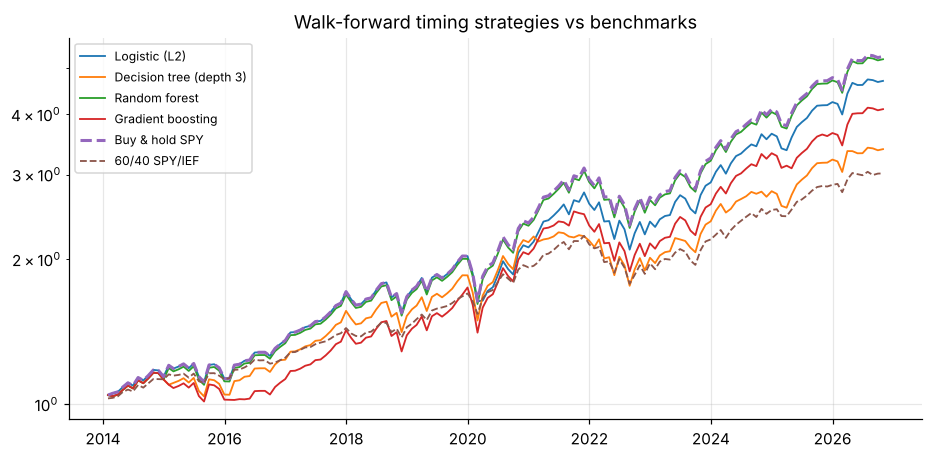

,CAGR,vol,Sharpe (vs 0),max DD
Logistic (L2),12.8%,14.0%,0.93,-23.9%
Decision tree (depth 3),10.0%,13.8%,0.76,-22.6%
Random forest,13.7%,14.4%,0.97,-23.9%
Gradient boosting,11.6%,14.1%,0.85,-24.9%
Buy & hold SPY,13.8%,14.4%,0.98,-23.9%
60/40 SPY/IEF,9.0%,9.3%,0.98,-20.5%


In [5]:
m = px[["SPY", "IEF"]].resample("ME").last().pct_change()
nxt = m.shift(-1)                                        # next month's returns, aligned to decision date
curves, stats = {}, {}
def perf(r):
    w = (1 + r).cumprod(); yrs = len(r) / 12
    return {"CAGR": w.iloc[-1] ** (1 / yrs) - 1, "vol": r.std() * np.sqrt(12),
            "Sharpe (vs 0)": r.mean() / r.std() * np.sqrt(12), "max DD": (w / w.cummax() - 1).min()}
for k, p in probs.items():
    r = np.where(p > 0.5, nxt.loc[p.index, "SPY"], nxt.loc[p.index, "IEF"])
    r = pd.Series(r, index=p.index).dropna()
    curves[k], stats[k] = (1 + r).cumprod(), perf(r)
bh = nxt.loc[r.index, "SPY"]; curves["Buy & hold SPY"], stats["Buy & hold SPY"] = (1 + bh).cumprod(), perf(bh)
mix = 0.6 * nxt.loc[r.index, "SPY"] + 0.4 * nxt.loc[r.index, "IEF"]; curves["60/40 SPY/IEF"], stats["60/40 SPY/IEF"] = (1 + mix).cumprod(), perf(mix)
for k, c in curves.items(): plt.plot(c, lw=2 if "Buy" in k else 1.2, ls="--" if "Buy" in k or "60" in k else "-", label=k)
plt.yscale("log"); plt.title("Walk-forward timing strategies vs benchmarks"); plt.legend(fontsize=8)
plt.savefig(IMG / "regime_timing.png", bbox_inches="tight"); plt.show()
pd.DataFrame(stats).T.style.format({"CAGR": "{:.1%}", "vol": "{:.1%}", "Sharpe (vs 0)": "{:.2f}", "max DD": "{:.1%}"})

## What do the models look at?

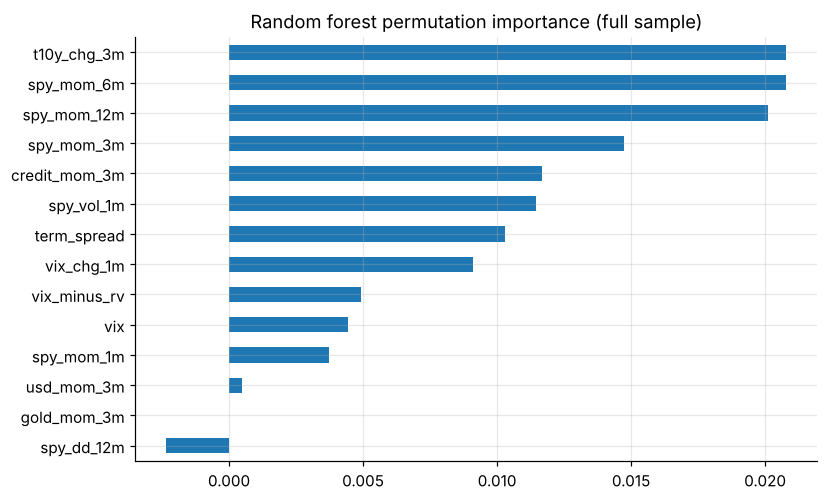

In [6]:
full = data.drop(columns="y"), data["y"]
rf = clone_rf = RandomForestClassifier(**models["Random forest"].get_params()).fit(*full)
from sklearn.inspection import permutation_importance
imp = permutation_importance(rf, *full, n_repeats=20, random_state=0)
pd.Series(imp.importances_mean, index=full[0].columns).sort_values().plot.barh(figsize=(8, 5))
plt.title("Random forest permutation importance (full sample)"); plt.savefig(IMG / "rf_importance.png", bbox_inches="tight"); plt.show()

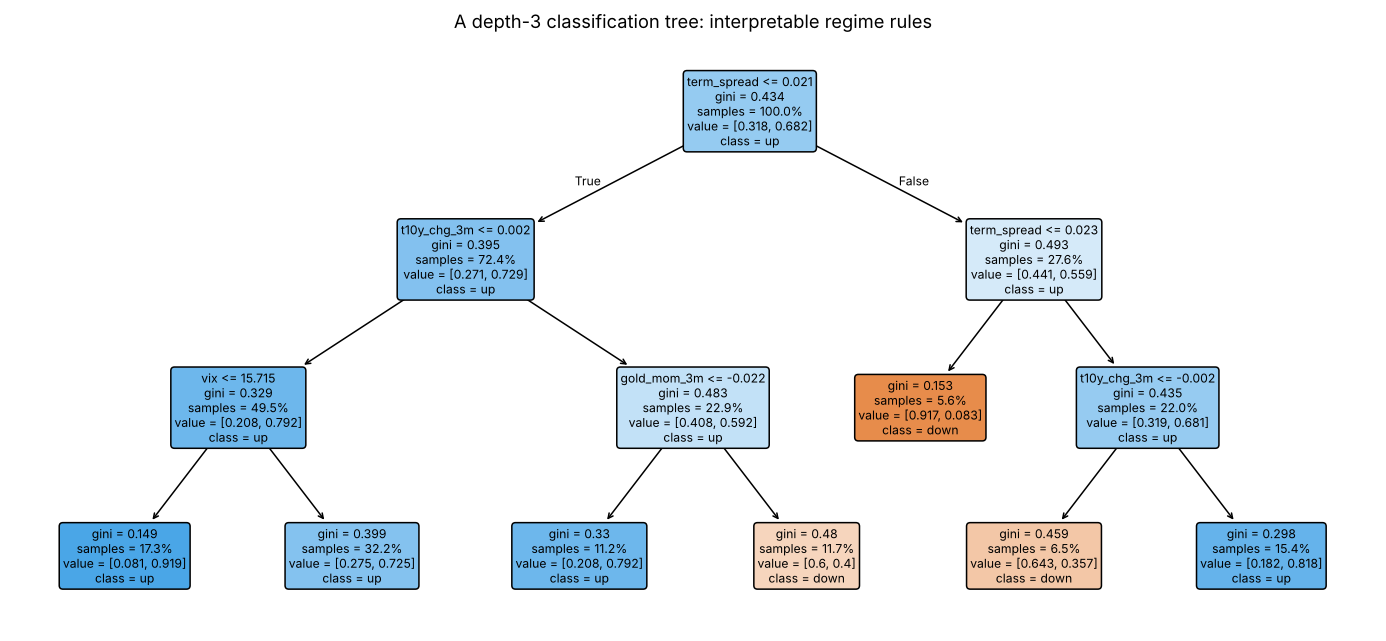

In [7]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=12, random_state=0).fit(*full)
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=list(full[0].columns), class_names=["down", "up"], filled=True, rounded=True, fontsize=8, proportion=True)
plt.title("A depth-3 classification tree: interpretable regime rules"); plt.savefig(IMG / "decision_tree.png", bbox_inches="tight"); plt.show()

### Conclusions
* **No model shows out-of-sample skill.** Walk-forward AUCs are *below* 0.5 and accuracies are at or under the "always up" base rate (~69%). Monthly equity direction from these indicators is not predictable in this sample.
* In-sample AUCs are much higher, so the gap is pure **overfitting**. That is exactly what a walk-forward design exposes.
* The timing strategies end up close to buy-and-hold because the models stay invested most of the time, and none reduces the maximum drawdown meaningfully.
* The single tree still produces readable rules, mainly about rates (term spread, 3-month change in the 10-year yield) plus VIX and gold momentum. They are useful for **describing** regimes, even though they do not **predict** them. Possible extensions: daily or weekly horizons, drawdown-probability targets rather than direction, and regime-conditional allocation instead of all-in/all-out switching.